# Building a Movie Recommendation System
## Milestone 3: Low-Rank Prediction with the SVD
*MATH 344L Applied Linear Algebra Lab*

Goal. Use the SVD to find patterns in the user by movie rating matrix and see if a low-rank model
can beat the user and movie effects baseline from Milestone 2. Most of the matrix is missing, so
every model has to make some temporary guess for the gaps before an SVD can be computed.

Model settings like the rank k are chosen with a validation set carved out of the training data.
The test set is only used once at the very end, so it stays an honest check.

---
## Part A: Load the project functions and data

In [1]:
import os
import subprocess
import sys

USER = "cmbright1015"
REPO = "movie-recommender-svd"

if os.path.exists(REPO):
    subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
    subprocess.run(
        ["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],
        check=True)

sys.path.insert(0, f"{REPO}/src")
from evaluate import split_ratings, to_matrix, rmse
from models import bias_baseline

This cell downloads my GitHub repository, or updates it with git pull if the folder is already
there. sys.path.insert tells Python to look in the src folder, so the functions saved in Milestone 2
can be imported instead of copied into this notebook again. split_ratings, to_matrix, and rmse come
from evaluate.py and bias_baseline comes from models.py.

In [2]:
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip")
    zipfile.ZipFile("ml-100k.zip").extractall()

ratings = pd.read_csv(
    "ml-100k/u.data", sep="\t",
    names=["user", "item", "rating", "time"])

train, test = split_ratings(ratings, seed=0)
fit, val = split_ratings(train, seed=1)
print("fit:", len(fit), "validation:", len(val), "test:", len(test))

fit: 81200 validation: 8832 test: 9968


This downloads MovieLens 100K if it is not already here and reads the ratings into a table. Then
the data gets split twice. The first split hides about 10% of the ratings as the test set, using the
same seed 0 as Milestone 2, so the test set is exactly the same 9,968 ratings. The second split
takes about 10% of what is left as a validation set, and the rest is the fitting set.

The fitting set is used to build models, the validation set is used to choose between them, and the
test set is used once at the end. The ml-100k folder is only downloaded for this session and is not
added to GitHub.

---
## Part B: Set up a fair validation comparison

In [3]:
R_fit = to_matrix(fit)
known_fit = ~np.isnan(R_fit)
val_truth = val["rating"].to_numpy()
val_u = val["user"].to_numpy() - 1
val_i = val["item"].to_numpy() - 1

def score_at(P, rows, cols, truth):
    """RMSE for selected entries of a prediction matrix."""
    pred = np.clip(P[rows, cols], 1, 5)
    return rmse(pred, truth)

R_fit is the user by movie matrix built from the fitting ratings only, so no validation rating can
leak into an average or an SVD. val_u and val_i are the row and column of each validation rating.
score_at picks out one prediction for each of those positions with P[rows, cols], clips it to the 1
to 5 star range, and returns the RMSE against the real ratings.

---
## Part C: Build the baseline prediction matrix

In [4]:
def baseline_matrix(R):
    """Full matrix: overall mean plus user and movie effects."""
    mu, b_user, b_item = bias_baseline(R)
    return mu + b_user[:, None] + b_item[None, :]

B_fit = baseline_matrix(R_fit)
baseline_val_rmse = score_at(B_fit, val_u, val_i, val_truth)
print("Baseline validation RMSE:", round(baseline_val_rmse, 4))

Baseline validation RMSE: 0.9731


baseline_matrix turns the user and movie effects into a full 943 by 1682 prediction matrix.
b_user[:, None] is a column with one value per user and b_item[None, :] is a row with one value
per movie. NumPy broadcasting adds them so that every entry gets $\mu + b_{\text{user}} + b_{\text{item}}$.

The baseline here scores about 0.973 on validation. That is higher than the 0.9545 test score from
Milestone 2 because the effects are now computed from the smaller fitting set and scored on
different ratings. The SVD models have to beat 0.973 on validation.

---
## Part D: Create a rank-k helper

In [5]:
def rank_k(U, s, Vt, k):
    """Build a rank-k matrix from an already computed SVD."""
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

The SVD writes a matrix as $U \Sigma V^T$. rank_k keeps only the first k columns of U, the first k
singular values, and the first k rows of $V^T$, which gives the best rank k approximation of the
matrix.

$$A_k = \sum_{j=1}^{k} \sigma_j \, u_j v_j^T$$

Since the SVD is only computed once per model, trying many values of k just means slicing it in
different ways, which is fast.

---
## Part E: Model 1 fills gaps with movie averages

An SVD needs a complete matrix, so this model fills each missing rating with that movie's average
rating in the fitting data.

In [6]:
mu_fit = np.nanmean(R_fit)
n_item = known_fit.sum(axis=0)
item_mean = np.full(R_fit.shape[1], mu_fit)
has_rating = n_item > 0
item_mean[has_rating] = (
    np.nansum(R_fit, axis=0)[has_rating] / n_item[has_rating])

F = np.where(known_fit, R_fit, item_mean[None, :])
U1, s1, Vt1 = np.linalg.svd(F, full_matrices=False)

item_mean is each movie's average fitting rating, and a movie with no fitting ratings would get
the overall average instead. np.where keeps every known rating and puts the movie average in each
gap, so F has no missing entries. Then np.linalg.svd computes its SVD. full_matrices=False keeps
U at 943 by 943 instead of building extra columns we never use.

---
## Part F: Model 2 lets the SVD explain what the baseline misses

The baseline already covers the overall rating level, generous users, and popular movies. Model 2
gives the SVD only what is left over.

In [7]:
X_fit = np.where(known_fit, R_fit - B_fit, 0.0)
U2, s2, Vt2 = np.linalg.svd(X_fit, full_matrices=False)

At a known entry, R_fit - B_fit is how far the real rating is from the baseline prediction. At a
gap there is no observed deviation, so it is set to 0, which means "assume the baseline is right."
The SVD of X_fit looks for patterns in these deviations, like a group of users who all rate horror
movies higher than the baseline expects. A rank k prediction is the low-rank deviations added back
onto the baseline.

---
## Part G: Choose rank using validation RMSE

Both models are tried at several ranks and scored on the validation set. The test set is not
touched here.

In [8]:
ks = [1, 2, 3, 5, 10, 15, 20, 30, 50, 100]
val_err1, val_err2 = [], []

for k in ks:
    P1 = rank_k(U1, s1, Vt1, k)
    P2 = rank_k(U2, s2, Vt2, k) + B_fit
    val_err1.append(score_at(P1, val_u, val_i, val_truth))
    val_err2.append(score_at(P2, val_u, val_i, val_truth))

best_k1 = ks[int(np.argmin(val_err1))]
best_k2 = ks[int(np.argmin(val_err2))]
print("Best Model 1 k:", best_k1, "validation RMSE:", min(val_err1))
print("Best Model 2 k:", best_k2, "validation RMSE:", min(val_err2))

Best Model 1 k: 15 validation RMSE: 0.9934477108911387
Best Model 2 k: 15 validation RMSE: 0.9492241710885614


For each k the loop builds a rank k prediction matrix for both models and scores it on validation.
Model 2 adds B_fit back because its low-rank matrix is made of deviations and not star ratings.
np.argmin gives the position of the smallest error, and ks at that position is the chosen rank.

Both models do best at k = 15. Model 1 gets about 0.993, which is worse than the baseline.
Model 2 gets about 0.949, which beats the baseline's 0.973.

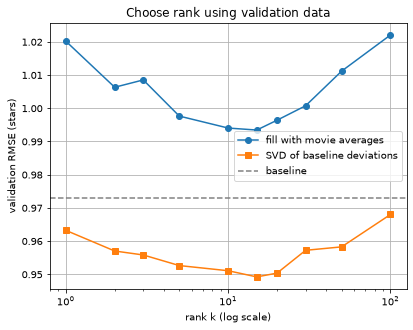

In [9]:
plt.semilogx(ks, val_err1, "o-", label="fill with movie averages")
plt.semilogx(ks, val_err2, "s-", label="SVD of baseline deviations")
plt.axhline(baseline_val_rmse, color="gray", linestyle="--",
            label="baseline")
plt.xlabel("rank k (log scale)")
plt.ylabel("validation RMSE (stars)")
plt.title("Choose rank using validation data")
plt.grid()
plt.legend()
plt.savefig("validation_rmse_vs_k.png", dpi=150)
plt.show()

The dashed line is the baseline. Model 1 stays above it at every rank, so filling the gaps with
movie averages and taking an SVD never beats the simple user and movie effects. Model 2 is below
the line at every rank. Both curves dip and then rise again. A very small k misses real patterns,
while a large k starts fitting noise and the made up values in the gaps. The plot is saved as
validation_rmse_vs_k.png and copied into the figures folder.

---
## Part H: Model 3 iteratively improves the missing-value guesses

Model 2 guessed 0 for every missing deviation. Model 3 starts the same way, but then keeps
replacing the gaps with its own rank k guesses.

In [10]:
def iterative_svd_predict(R, k, n_iter=10):
    """Predict ratings by repeatedly imputing missing deviations."""
    known = ~np.isnan(R)
    B = baseline_matrix(R)
    X = np.where(known, R - B, 0.0)

    for _ in range(n_iter):
        U, s, Vt = np.linalg.svd(X, full_matrices=False)
        L = rank_k(U, s, Vt, k)
        X = np.where(known, R - B, L)

    return L + B

Each round computes an SVD of X, builds the rank k approximation L, and then np.where puts the
real training deviations back at the known entries while keeping L only in the gaps. So the known
ratings never change, and the guesses in the gaps get refined each round. After the last round the
baseline is added back. With n_iter=1 this is the same as Model 2.

In [11]:
ks_iter = [2, 5, 10, 20]
val_err3 = []

for k in ks_iter:
    P3 = iterative_svd_predict(R_fit, k, n_iter=10)
    val_err3.append(score_at(P3, val_u, val_i, val_truth))

best_k3 = ks_iter[int(np.argmin(val_err3))]
print("Best iterative rank:", best_k3)
print("Best validation RMSE:", min(val_err3))

Best iterative rank: 2
Best validation RMSE: 0.9431464026691649


Each rank needs 10 new SVDs, so only four ranks are tried. Rank 2 does best with a validation
RMSE of about 0.943. That beats Model 2's best of 0.949, Model 1's best of 0.993, and the
baseline's 0.973. Model 3 likes a lower rank than Model 2, probably because the repeated
imputation lets a few strong patterns do more of the work, while larger ranks start chasing noise
in the gaps.

---
## Part I: Refit and evaluate on the test set once

The model and rank are chosen from the validation results only. Now the chosen model is rebuilt
from all of the training ratings and scored on the hidden test set.

In [12]:
R_train = to_matrix(train)
test_truth = test["rating"].to_numpy()
test_u = test["user"].to_numpy() - 1
test_i = test["item"].to_numpy() - 1

B_train = baseline_matrix(R_train)
test_baseline = score_at(B_train, test_u, test_i, test_truth)

if min(val_err3) < min(val_err2) and min(val_err3) < min(val_err1):
    test_prediction = iterative_svd_predict(
        R_train, best_k3, n_iter=10)
    chosen_model = "iterative SVD"
elif min(val_err2) < min(val_err1):
    known_train = ~np.isnan(R_train)
    X_train = np.where(known_train, R_train - B_train, 0.0)
    U, s, Vt = np.linalg.svd(X_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k2) + B_train
    chosen_model = "baseline plus low-rank deviations"
else:
    known_train = ~np.isnan(R_train)
    mu_train = np.nanmean(R_train)
    n_item_train = known_train.sum(axis=0)
    means_train = np.full(R_train.shape[1], mu_train)
    has_train = n_item_train > 0
    means_train[has_train] = (
        np.nansum(R_train, axis=0)[has_train] / n_item_train[has_train])
    F_train = np.where(known_train, R_train, means_train[None, :])
    U, s, Vt = np.linalg.svd(F_train, full_matrices=False)
    test_prediction = rank_k(U, s, Vt, best_k1)
    chosen_model = "SVD of movie-average-filled matrix"

test_rmse = score_at(test_prediction, test_u, test_i, test_truth)
print("Chosen model:", chosen_model)
print("Baseline test RMSE:", round(test_baseline, 4))
print("Chosen model test RMSE:", round(test_rmse, 4))

Chosen model: iterative SVD
Baseline test RMSE: 0.9545
Chosen model test RMSE: 0.9286


The if statement picks whichever model had the lowest validation RMSE, which is the iterative SVD
at rank 2. The model is refit on R_train, which has all 90,032 training ratings, including the ones
that were used for validation. Then it is scored once on the 9,968 test ratings, the same ones used
in Milestone 2.

The iterative SVD gets a test RMSE of about 0.929, compared to 0.9545 for the baseline. That is
an improvement of about 0.026 stars. In Milestone 2 Exercise 3, changing the split moved scores
by up to about 0.02, so this gain is a bit bigger than that kind of noise. This result is not used
to change the model or the rank, since that would turn the test set into another validation set.

---
## Part J: Make a few recommendations

In [13]:
item_info = pd.read_csv(
    "ml-100k/u.item", sep="|", header=None, usecols=[0, 1],
    encoding="latin-1")
item_info.columns = ["item", "title"]

user_id = 1
user_row = user_id - 1
unrated = np.where(np.isnan(R_train[user_row]))[0]
predicted_scores = np.clip(test_prediction[user_row], 1, 5)
top = unrated[np.argsort(predicted_scores[unrated])[-5:][::-1]]

for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(title, "predicted rating:", round(predicted_scores[col], 2))

Great Day in Harlem, A (1994) predicted rating: 5.0
Saint of Fort Washington, The (1993) predicted rating: 5.0
Pulp Fiction (1994) predicted rating: 5.0
Aiqing wansui (1994) predicted rating: 5.0
Santa with Muscles (1996) predicted rating: 5.0


The prediction matrix has a score for every user and movie. For user 1, unrated lists the movies
they did not rate in training, and np.argsort sorts their predicted scores so the last five are the
highest. The matrix columns start at 0 and MovieLens IDs start at 1, so the code adds 1 to look up
each title.

All five top movies get a clipped score of 5.0, and most of them are obscure. That points to a
weakness. A movie with only one or two ratings can get a huge movie effect from a single 5 star
rating, so it ends up at the top of everyone's list. Exercise 6 checks how many ratings these
movies have. A high predicted score does not prove user 1 will like the movie. RMSE measures
accuracy over thousands of hidden ratings, not the quality of one top five list.

---
## Practice Exercises

### Exercise 1: Does filling matter?

In [14]:
fills = {
    "movie average": item_mean[None, :],
    "overall average": mu_fit,
    "3 stars": 3.0,
    "0 stars": 0.0,
}
fill_ks = [5, 10, 20, 50]
fill_table = {}

for name, value in fills.items():
    F_try = np.where(known_fit, R_fit, value)
    U_f, s_f, Vt_f = np.linalg.svd(F_try, full_matrices=False)
    fill_table[name] = [
        score_at(rank_k(U_f, s_f, Vt_f, k), val_u, val_i, val_truth)
        for k in fill_ks]

pd.DataFrame(fill_table, index=[f"k = {k}" for k in fill_ks]).round(4)

,movie average,overall average,3 stars,0 stars
k = 5,0.9976,1.0568,1.0856,2.4036
k = 10,0.9940,1.0511,1.0749,2.3434
k = 20,0.9964,1.0545,1.0788,2.3508
k = 50,1.0112,1.0716,1.1210,2.4913


Filling with the movie average works best at every rank, then the overall average, then 3 stars.
The movie average carries real information about each movie, so the filled matrix is already close
to the truth before the SVD even starts. The overall average and 3 stars put the same number in
every gap, so the SVD has to work harder, and 3 stars is worse because real ratings lean positive.

Filling with 0 is a really bad choice, with RMSE around 2.35 or worse. Zero stars is not even on
the 1 to 5 scale. Since about 95% of the matrix is missing, the SVD mostly learns the pattern of
which movies were rated, and it predicts that unrated movies are terrible. It treats "has not seen
it" as "hated it."

### Exercise 2: Understand the full-rank check

In [15]:
full = len(s2)
P_full = rank_k(U2, s2, Vt2, full) + B_fit
gaps = ~known_fit

print("Full rank:", full)
print("Rebuilds X_fit:", np.allclose(rank_k(U2, s2, Vt2, full), X_fit))
print("Equals baseline at the gaps:", np.allclose(P_full[gaps], B_fit[gaps]))
print("Full rank validation RMSE:",
      round(score_at(P_full, val_u, val_i, val_truth), 4))
print("Baseline validation RMSE: ", round(baseline_val_rmse, 4))

Full rank: 943
Rebuilds X_fit: True
Equals baseline at the gaps: True
Full rank validation RMSE: 0.9731
Baseline validation RMSE:  0.9731


X_fit is 943 by 1682, so it has at most 943 singular values. Keeping all of them gives
$U \Sigma V^T$ exactly, which is X_fit itself. That matrix has 0 in every gap because that is what
we filled it with. Adding B_fit back means every gap is predicted as baseline plus 0, which is just
the baseline. The code confirms it, and the full rank validation RMSE is exactly the baseline's
0.9731.

So the full rank model did not learn any preferences. It just memorized the training deviations
and repeated our fill value at the gaps. The useful part of the SVD comes from throwing away the
small singular values. A low rank forces the model to describe all users with a few shared
patterns, and then those patterns give nonzero guesses in the gaps. With all ranks kept there is
no compression and so nothing to generalize from.

### Exercise 3: Study iteration

In [16]:
rounds = [1, 2, 5, 10]
round_err = []

for n in rounds:
    P = iterative_svd_predict(R_fit, 5, n_iter=n)
    round_err.append(score_at(P, val_u, val_i, val_truth))

pd.Series(round_err, index=rounds, name="validation RMSE (k = 5)").round(4)

1     0.9526
2     0.9456
5     0.9411
10    0.9433
Name: validation RMSE (k = 5), dtype: float64

One round is the same as Model 2 at rank 5, 0.9526. Two rounds help a lot and five rounds give the
best score, about 0.941. Going to 10 rounds makes it slightly worse, 0.9433. So more iteration does
not always help. Each round makes the gap guesses fit the known ratings more closely, and after a
while that starts fitting noise in the fitting set instead of real patterns. The number of rounds is
really another setting that should be chosen with validation data, just like k.

### Exercise 4: Check for overfitting

In [17]:
summary = pd.DataFrame({
    "Model 1": pd.Series(val_err1, index=ks),
    "Model 2": pd.Series(val_err2, index=ks),
    "Model 3": pd.Series(val_err3, index=ks_iter),
})
summary.index.name = "rank k"
print("Final test RMSE of", chosen_model + ":", round(test_rmse, 4))
summary.round(4)

Final test RMSE of iterative SVD: 0.9286


,Model 1,Model 2,Model 3
rank k,,,
1,1.0202,0.9632,NaN
2,1.0063,0.9570,0.9431
3,1.0085,0.9558,NaN
5,0.9976,0.9526,0.9433
10,0.9940,0.9511,0.9588
15,0.9934,0.9492,NaN
20,0.9964,0.9504,0.9769
30,1.0008,0.9572,NaN
50,1.0112,0.9583,NaN


Across the ranks, every model has a U shaped validation curve. Small ranks underfit, and larger
ranks overfit, with Model 2 going from 0.949 at k = 15 up to 0.968 at k = 100 and Model 3 going
from 0.943 at k = 2 up to 0.977 at k = 20. The large ranks match the fitting ratings better but
predict new ratings worse.

The final test RMSE of 0.929 is actually lower than the best validation RMSE of 0.943. The refit
model used all of train, about 9,000 more ratings than the fitting set, so it has more to learn
from. The validation and test sets are also different ratings, and some sets are easier than others.

The rank should be picked before looking at test performance because the test score is supposed to
estimate how the model does on ratings it has never seen. If we tried every k on the test set and
kept the best, we would be choosing the k that happens to fit those particular 9,968 ratings, and
the score would look better than the model really is. That is the same data leakage from Milestone
2, just one step removed.

### Exercise 5: Cold-start limitation

A new user has an empty row with no ratings. Their user effect cannot be computed, and in our code
np.nanmean of an empty row gives nan, so the whole row of predictions would be nan. The SVD cannot
help either, because there are no known entries to place the user in the low-rank patterns. The
most reasonable prediction is $\mu + b_{\text{item}}$, the overall mean plus each movie's effect,
which recommends the same well liked movies to every new user.

Things that would help include asking a new user to rate a handful of popular movies when they sign
up, using basic information like age, gender, or occupation from the u.user file, using movie
genres from u.item, or using implicit data like which movies they clicked on or watched.

### Exercise 6: Explain the result

In [18]:
n_train = (~np.isnan(R_train)).sum(axis=0)

for col in top:
    title = item_info.loc[item_info["item"] == col + 1, "title"].iloc[0]
    print(f"{title:40s} training ratings: {n_train[col]}")

Great Day in Harlem, A (1994)            training ratings: 1
Saint of Fort Washington, The (1993)     training ratings: 2
Pulp Fiction (1994)                      training ratings: 349
Aiqing wansui (1994)                     training ratings: 1
Santa with Muscles (1996)                training ratings: 2


The baseline predicts each rating as the overall mean plus a user effect and a movie effect, and it
is off by about 0.95 stars on the test set. The iterative SVD at rank 2 adds a low-rank pattern of
deviations on top of the baseline and gets 0.929, about 0.026 stars better. So people's tastes
really do have some shared structure that a few singular vectors can capture, but most of what is
predictable is already in the simple user and movie effects.

The recommendations show what the model scores highest for user 1, not what user 1 will actually
enjoy. Four of the five top movies have only one or two training ratings, so their high scores come
from a tiny amount of data and could easily be luck. Pulp Fiction, with 349 ratings, is the only
pick that is backed by a lot of data. A better recommender would shrink the effect
of movies with few ratings toward the average, or require a minimum number of ratings before
recommending a movie. RMSE tells us the model is more accurate on average, but it does not tell us
whether any single top five list is good.